# Marsline · Feature engineering for the Jezero Crater map

**NASA Space Apps 2026 · Interplanetary Survival Guide: Martian Map**

This notebook turns the raw NASA/USGS files in `Marsline_NASA_Resources.zip` into small,
browser-ready layers that the Marsline app loads from `public/data/jezero/`.

| Step | Raw data | Engineered feature | Used in the app for |
|---|---|---|---|
| 1 | HRSC DEM (75 m, in `USGS_Geology`) | **slope, roughness, elevation** | safety, route cost |
| 2 | USGS Jezero/Nili geologic map (`.gdb`) | **terrain-cost + science-value rasters**, GeoJSON overlays | hazards, science targets |
| 3 | CTX mosaic + THEMIS day/night IR | **optical + thermal layers** | context imagery |
| 4 | Steps 1–3 combined | **traversability classes + route cost grid** | route planner (A*) |
| 5 | MOLA global DEM | **cross-check** of HRSC elevations | data-quality validation |
| 6 | MEDA index CSVs | **sol / season / local-time coverage** | conditions page |

Everything is computed in the map's native metric projection (Mars MTM, central meridian 77.5°E),
so slopes are in real degrees, then warped to a regular longitude/latitude grid for the web map.

> **Assumptions are marked `ASSUMPTION`.** Slope limits and geologic-unit costs/science scores are
> engineering choices for this concept, not NASA-certified numbers. Tune them in the config cells.

## 0 · Setup
Needs `geopandas`, `pyogrio`, `pyproj`, `shapely`, `tifffile`, `imagecodecs` in addition to Anaconda's numpy/scipy/pandas/Pillow/matplotlib.
If an import fails, run **one** of these in a terminal, then restart the kernel:
```
conda install -c conda-forge geopandas pyogrio pyproj shapely tifffile imagecodecs
# or
pip install geopandas pyogrio pyproj shapely tifffile imagecodecs
```

In [1]:
import os, json, math, zipfile, shutil, warnings
os.environ["PROJ_IGNORE_CELESTIAL_BODY"] = "YES"   # PROJ otherwise refuses Mars <-> Earth CRS mixing
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
from matplotlib import cm
from scipy import ndimage as ndi

try:
    import tifffile, shapely, geopandas as gpd
    from pyproj import CRS, Transformer
    from shapely.geometry import mapping, box
    from shapely.ops import transform as shp_transform
except ImportError as e:
    raise SystemExit(f"Missing package: {e.name}. See the install note above.")

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "package.json").exists())
ZIP_PATH = Path(os.environ.get("MARSLINE_ZIP", Path.home() / "Downloads" / "Marsline_NASA_Resources.zip"))
RAW = ROOT / "data" / "raw"                      # git-ignored (hundreds of MB)
OUT = ROOT / "public" / "data" / "jezero"         # small outputs the app serves
RAW.mkdir(parents=True, exist_ok=True); OUT.mkdir(parents=True, exist_ok=True)
print("project:", ROOT, "\nzip:", ZIP_PATH, ZIP_PATH.exists())

R_MARS = 3396190.0                                # Mars 2000 sphere radius used by the USGS map (m)
M_PER_DEG = R_MARS * math.pi / 180

# --- ASSUMPTION: mobility limits for a suited astronaut / unpressurised rover ---------------------
SLOPE_BLOCK_DEG = 25.0      # >= this: no-go
SLOPE_CAUTION_DEG = 15.0    # >= this: caution
ROUGH_CAUTION_M = 3.0       # local elevation std-dev (5x5 window) above which terrain is flagged rough

project: /Users/poornapiumini/Documents/Marsline 
zip: /Users/poornapiumini/Downloads/Marsline_NASA_Resources.zip True


## 1 · Unpack only what we need
The zip holds ~600 MB. We extract the MOLA tile and the useful parts of the USGS database
(geodatabase + CTX/THEMIS/HRSC rasters; the 6 m ORTHO and 20 m DTMs use another projection and are skipped).

In [2]:
def extract_inputs():
    marker = RAW / ".extracted"
    if marker.exists():
        return
    assert ZIP_PATH.exists(), f"Put the zip at {ZIP_PATH} or set MARSLINE_ZIP"
    base = "Marsline_NASA_Resources/"
    with zipfile.ZipFile(ZIP_PATH) as z:
        for n in ["MOLA/megt44n000hb.img", "MOLA/megt44n000hb.lbl", "USGS_Geology/sim3464_database.zip"]:
            z.extract(base + n, RAW / "_tmp")
    shutil.move(RAW / "_tmp" / base / "MOLA", RAW / "MOLA")
    inner = RAW / "_tmp" / base / "USGS_Geology" / "sim3464_database.zip"
    keep = ("Geodatabase/", "CoordinateSystems/", "Rasters/HRSC/nili_h0988", "Rasters/Caltech_CTX_mosaic_feb2018/",
            "Rasters/USGS_THEMIS_IR_controlled_mosaic_oct2018/")
    with zipfile.ZipFile(inner) as z:
        for m in z.namelist():
            rel = m.split("/", 1)[-1]
            if m.startswith("__MACOSX") or m.endswith((".lock", ".ovr", ".DS_Store")) or m.endswith("/"):
                continue
            if rel.startswith(keep):
                z.extract(m, RAW / "usgs")
    shutil.rmtree(RAW / "_tmp")
    marker.write_text("ok")

extract_inputs()
USGS = next((RAW / "usgs").iterdir())
GDB = USGS / "Geodatabase" / "Nili.gdb"
print("geodatabase:", GDB.exists(), "| rasters:", sorted(p.name for p in (USGS / "Rasters").rglob("*.tif")))

geodatabase: True | rasters: ['Nili_CTX_Mosaic_Beta01_Feb2018_MTM.tif', 'nili_THEMIS_DayIR_Controlled_oct2018.tif', 'nili_THEMIS_NightIR_Controlled_oct2018.tif', 'nili_h0988_0000_da4_clip.tif', 'nili_h0988_0000_hillshade_clip.tif']


## 2 · Coordinate systems
The USGS map and its rasters use **Mars MTM (Transverse Mercator, central meridian 77.5°E)**. We analyse in MTM metres
and only convert to longitude/latitude for display.

In [3]:
MTM = CRS.from_wkt(next((USGS / "CoordinateSystems").glob("MTM_clon77_5E.prj")).read_text())
LL = CRS.from_proj4(f"+proj=longlat +R={R_MARS} +no_defs")
to_ll = Transformer.from_crs(MTM, LL, always_xy=True)
to_mtm = Transformer.from_crs(LL, MTM, always_xy=True)

def read_geotiff(path):
    """Return (array, x0, y0, res): top-left corner and square pixel size in MTM metres."""
    with tifffile.TiffFile(path) as t:
        pg = t.pages[0]
        sx = pg.tags["ModelPixelScaleTag"].value[0]; tp = pg.tags["ModelTiepointTag"].value
        return pg.asarray(), tp[3], tp[4], sx

r = USGS / "Rasters"
dem_raw, X0, Y0, RES = read_geotiff(r / "HRSC" / "nili_h0988_0000_da4_clip.tif")
H, W = dem_raw.shape
print(f"HRSC DEM grid {W}x{H} @ {RES:.0f} m | extent {W*RES/1000:.1f} x {H*RES/1000:.1f} km | dtype {dem_raw.dtype} | range {dem_raw.min()}..{dem_raw.max()}")

HRSC DEM grid 753x791 @ 75 m | extent 56.5 x 59.3 km | dtype int16 | range -32768..-1413


## 3 · Terrain features from the HRSC DEM (75 m)
* **Slope** (Horn's method, same as GDAL/ArcGIS) – how steep the ground is for a walking astronaut.
* **Roughness** – local standard deviation of elevation after removing the broad trend (a proxy for rocky/uneven ground).
* **Elevation** – kept for elevation-gain estimates along routes.

In [4]:
dem = dem_raw.astype(np.float32)
bad = dem < -9000                                        # no-data safeguard
if bad.any():
    idx = ndi.distance_transform_edt(bad, return_distances=False, return_indices=True)
    dem = dem[tuple(idx)]

def horn_slope(z, res):
    dzdx = ndi.sobel(z, axis=1) / (8 * res)
    dzdy = ndi.sobel(z, axis=0) / (8 * res)
    return np.degrees(np.arctan(np.hypot(dzdx, dzdy)))

def roughness(z, win=5):
    resid = z - ndi.uniform_filter(z, win * 2 - 1)
    m = ndi.uniform_filter(resid, win); m2 = ndi.uniform_filter(resid ** 2, win)
    return np.sqrt(np.maximum(m2 - m ** 2, 0))

slope = horn_slope(dem, RES)
rough = roughness(dem)
print(f"slope: median {np.median(slope):.1f}°, p95 {np.percentile(slope,95):.1f}°, max {slope.max():.1f}° | "
      f"roughness median {np.median(rough):.2f} m")

slope: median 2.9°, p95 12.7°, max 45.1° | roughness median 1.44 m


## 4 · Geology → terrain cost and science value
The USGS map (SIM 3464) gives geologic units, linear features (ridges, rim crests, delta fronts), surface features and craters.

`ASSUMPTION`: the table below converts each unit to a **terrain-cost multiplier** (loose sand and rugged ground are slower
and riskier on foot) and a **science value 0–1** (how much a mission scientist would want to visit). Edit freely.

In [5]:
UNIT_RULES = {
    #  name                      cost  science  why
    "Jezero fan 1 unit":        (1.1, 1.00, "Delta deposit: water-lain sediments, prime astrobiology target"),
    "Jezero fan 2 unit":        (1.1, 0.95, "Younger delta deposit: stratigraphy of the Jezero lake system"),
    "Nili Planum fan unit":     (1.1, 0.70, "Fan deposit outside the crater"),
    "Upper etched unit":        (1.3, 0.80, "Layered, eroded bedrock: mineral-rich layers"),
    "Lower etched unit":        (1.3, 0.80, "Layered, eroded bedrock: older record"),
    "Jezero floor unit":        (1.0, 0.65, "Crater floor: flat, easy access, igneous/sedimentary mix"),
    "Crater interior unit":     (1.2, 0.55, "Crater interior materials"),
    "Crater rim unit":          (1.5, 0.70, "Uplifted ancient crust (megabreccia): steep, blocky"),
    "Crater ejecta unit":       (1.4, 0.50, "Impact ejecta: boulder-rich"),
    "Nili Planum 1 unit":       (1.2, 0.50, "Ancient plateau bedrock"),
    "Nili Planum 2 unit":       (1.2, 0.50, "Ancient plateau bedrock"),
    "Smooth unit, undivided":   (1.0, 0.30, "Smooth cover: easy walking"),
    "Rugged bright unit":       (1.6, 0.40, "Rough bright bedrock: slow, tripping hazard"),
    "Eolian bedform unit":      (1.8, 0.10, "Dunes/ripples: loose sand, wheel/boot entrapment"),
}
DEFAULT_COST, DEFAULT_SCIENCE = 1.2, 0.2
UNIT_NAMES = list(UNIT_RULES)
FEATURE_COST = {"ridged": 1.8, "dark-colored mantling material": 1.3}          # SurfaceFeatures polygons
BARRIER_LINES = ("ridge crest", "crest of crater rim", "delta lobe front")      # LinearFeatures treated as scarps/obstacles

units = gpd.read_file(GDB, layer="GeoUnits_v1")
units["name"] = units["name"].str.replace("riim", "rim").str.strip()
surf = gpd.read_file(GDB, layer="SurfaceFeatures")
lines = gpd.read_file(GDB, layer="LinearFeatures")
craters = gpd.read_file(GDB, layer="LocationFeatures")
ellipse = gpd.read_file(GDB, layer="LandingEllipse")
print(len(units), "units;", units["name"].nunique(), "unit types;", len(lines), "linear features;", len(craters), "craters")

1304 units; 14 unit types; 382 linear features; 341 craters


In [6]:
def pxy(c):  # MTM -> fractional pixel (col,row), pixel corners
    return ((c[0] - X0) / RES, (Y0 - c[1]) / RES)

def burn_polygons(geoms, values):
    """Rasterise polygons (largest first so small units sit on top) onto the DEM grid. NaN where uncovered."""
    out = np.full((H, W), np.nan, np.float32)
    for i in np.argsort([-g.area for g in geoms]):
        g = geoms[i]
        if g is None or g.is_empty: continue
        for p in (g.geoms if g.geom_type == "MultiPolygon" else [g]):
            minx, miny, maxx, maxy = p.bounds
            c0, c1 = max(int((minx - X0) // RES) - 1, 0), min(int((maxx - X0) // RES) + 2, W)
            r0, r1 = max(int((Y0 - maxy) // RES) - 1, 0), min(int((Y0 - miny) // RES) + 2, H)
            if c1 <= c0 or r1 <= r0: continue
            im = Image.new("L", (c1 - c0, r1 - r0), 0); d = ImageDraw.Draw(im)
            d.polygon([(pxy(c)[0] - c0, pxy(c)[1] - r0) for c in p.exterior.coords], fill=1)
            for h in p.interiors:
                d.polygon([(pxy(c)[0] - c0, pxy(c)[1] - r0) for c in h.coords], fill=0)
            out[r0:r1, c0:c1][np.array(im, bool)] = values[i]
    return out

def burn_lines(geoms, width=2):
    im = Image.new("L", (W, H), 0); d = ImageDraw.Draw(im)
    for g in geoms:
        for ln in (g.geoms if g.geom_type == "MultiLineString" else [g]):
            d.line([pxy(c) for c in ln.coords], fill=1, width=width)
    return np.array(im, bool)

unit_idx = burn_polygons(list(units.geometry), [UNIT_NAMES.index(n) if n in UNIT_NAMES else -1 for n in units["name"]])
unit_idx[unit_idx < 0] = np.nan
cost_tbl = np.array([UNIT_RULES[n][0] for n in UNIT_NAMES]); sci_tbl = np.array([UNIT_RULES[n][1] for n in UNIT_NAMES])
geo_cost = np.where(np.isnan(unit_idx), DEFAULT_COST, cost_tbl[np.nan_to_num(unit_idx, nan=0).astype(int)])
science = np.where(np.isnan(unit_idx), DEFAULT_SCIENCE, sci_tbl[np.nan_to_num(unit_idx, nan=0).astype(int)])

for typ, mult in FEATURE_COST.items():
    sel = surf[surf["TYPE"] == typ]
    if len(sel):
        m = ~np.isnan(burn_polygons(list(sel.geometry), [1.0] * len(sel)))
        geo_cost = np.where(m, np.maximum(geo_cost, mult), geo_cost)

barrier = burn_lines(lines[lines["TYPE"].str.startswith(BARRIER_LINES)].geometry, width=2)
print(f"unit coverage {np.mean(~np.isnan(unit_idx))*100:.0f}% of the DEM area | barrier pixels {barrier.sum()}")

unit coverage 100% of the DEM area | barrier pixels 10160


## 5 · Traversability classes and route cost
* **0 · No-go**: slope ≥ 25° or a ridge/rim/delta-front scarp line.
* **1 · Caution**: slope ≥ 15°, rough ground, or high-cost geology (≥ 1.5×).
* **2 · Nominal**.

`route_cost = geology cost × (1 + (slope/15°)²) × (1 + roughness/3 m)`, and no-go cells are impassable.
The app's A* planner reads this same grid.

In [7]:
cls = np.full((H, W), 2, np.uint8)
cls[(slope >= SLOPE_CAUTION_DEG) | (rough >= ROUGH_CAUTION_M) | (geo_cost >= 1.5)] = 1
cls[(slope >= SLOPE_BLOCK_DEG) | barrier] = 0
route_cost = geo_cost * (1 + (slope / SLOPE_CAUTION_DEG) ** 2) * (1 + rough / ROUGH_CAUTION_M)
share = {k: float((cls == v).mean()) for k, v in {"nogo": 0, "caution": 1, "nominal": 2}.items()}
print({k: f"{v*100:.1f}%" for k, v in share.items()})

{'nogo': '2.3%', 'caution': '30.0%', 'nominal': '67.7%'}


## 6 · Warp everything to a longitude/latitude grid for the web map
Because MTM is slightly rotated against the lon/lat graticule here (meridian convergence), we resample properly instead of just
stretching the image. Output pixel = ~75 m for analysis layers.

In [8]:
xs = np.r_[np.linspace(X0, X0 + W * RES, 60), np.full(60, X0 + W * RES), np.linspace(X0 + W * RES, X0, 60), np.full(60, X0)]
ys = np.r_[np.full(60, Y0), np.linspace(Y0, Y0 - H * RES, 60), np.full(60, Y0 - H * RES), np.linspace(Y0 - H * RES, Y0, 60)]
elon, elat = to_ll.transform(xs, ys)
WEST, EAST, SOUTH, NORTH = float(elon.min()), float(elon.max()), float(elat.min()), float(elat.max())
AOI = box(WEST, SOUTH, EAST, NORTH)

def make_grid(step_m):
    dlat = step_m / M_PER_DEG; dlon = dlat / math.cos(math.radians((SOUTH + NORTH) / 2))
    wd, ht = int(math.ceil((EAST - WEST) / dlon)), int(math.ceil((NORTH - SOUTH) / dlat))
    lon = WEST + (np.arange(wd) + 0.5) * dlon; lat = NORTH - (np.arange(ht) + 0.5) * dlat
    LON, LAT = np.meshgrid(lon, lat)
    X, Y = to_mtm.transform(LON, LAT)
    return dict(w=wd, h=ht, dlon=dlon, dlat=dlat, X=X, Y=Y, lon=lon, lat=lat)

G = make_grid(75)
print(f"bounds  W {WEST:.4f}  E {EAST:.4f}  S {SOUTH:.4f}  N {NORTH:.4f} | grid {G['w']}x{G['h']}")

def grid_bounds(g):
    """Exact outer edges [south, west, north, east] of a grid, so web overlays align pixel-for-pixel."""
    return [NORTH - g["h"] * g["dlat"], WEST, NORTH, WEST + g["w"] * g["dlon"]]

def warp(src, res, grid, x0=None, y0=None, order=1):
    x0 = X0 if x0 is None else x0; y0 = Y0 if y0 is None else y0
    col = (grid["X"] - x0) / res - 0.5; row = (y0 - grid["Y"]) / res - 0.5
    return ndi.map_coordinates(src.astype(np.float32), [row, col], order=order, mode="constant", cval=np.nan)

w_dem, w_slope, w_rough = (warp(a, RES, G) for a in (dem, slope, rough))
w_cls = warp(cls.astype(np.float32), RES, G, order=0)
w_geo, w_sci = warp(geo_cost, RES, G), warp(science, RES, G)
w_bar = warp(barrier.astype(np.float32), RES, G, order=0)
w_cost = warp(route_cost, RES, G)
w_bad = warp(bad.astype(np.float32), RES, G, order=0)          # DEM no-data (about 0.4 %) -> invalid
valid = ~np.isnan(w_dem) & (w_bad < 0.5)

bounds  W 76.7960  E 77.8018  S 17.6992  N 18.7013 | grid 756x792


## 7 · Optical and thermal layers (CTX, THEMIS day/night, HRSC hillshade)

In [9]:
def gray_png(a, valid, path, lo=None, hi=None, jpeg=False):
    lo = np.nanpercentile(a, 1) if lo is None else lo; hi = np.nanpercentile(a, 99) if hi is None else hi
    g = np.clip((np.nan_to_num(a) - lo) / (hi - lo + 1e-9), 0, 1)
    rgba = np.dstack([g, g, g, valid]).astype(np.float32); rgba[..., :3] *= 255; rgba[..., 3] *= 255
    im = Image.fromarray(rgba.astype(np.uint8), "RGBA")
    (im.convert("RGB").save(path, quality=80) if jpeg else im.save(path, optimize=True))

def tif(name): return read_geotiff(next(r.rglob(name)))

a, x0, y0, res = tif("nili_h0988_0000_hillshade_clip.tif")
w_hill = warp(a, res, G, x0, y0); gray_png(w_hill, ~np.isnan(w_hill), OUT / "hillshade.png", 0, 255)

a, x0, y0, res = tif("nili_THEMIS_DayIR_Controlled_oct2018.tif")
w_day = warp(a, res, G, x0, y0, order=1); gray_png(w_day, ~np.isnan(w_day), OUT / "themis_day.png")
a, x0, y0, res = tif("nili_THEMIS_NightIR_Controlled_oct2018.tif")
w_night = warp(a, res, G, x0, y0, order=1); gray_png(w_night, ~np.isnan(w_night), OUT / "themis_night.png")

a, x0, y0, res = tif("Nili_CTX_Mosaic_Beta01_Feb2018_MTM.tif")          # 5 m -> average to 20 m
k = 4; a = a[: a.shape[0] // k * k, : a.shape[1] // k * k]
a = a.reshape(a.shape[0] // k, k, a.shape[1] // k, k).mean(axis=(1, 3), dtype=np.float32)
GC = make_grid(20)
w_ctx = warp(a, res * k, GC, x0, y0); gray_png(w_ctx, ~np.isnan(w_ctx), OUT / "ctx.jpg", jpeg=True)
print("THEMIS day/night, hillshade, CTX written; CTX grid", GC["w"], "x", GC["h"])

THEMIS day/night, hillshade, CTX written; CTX grid 2832 x 2970


## 8 · Colour layers + data textures for the app
* `elevation.png`, `slope.png`, `traversability.png`, `science.png` – coloured display layers.
* `grid_data.png` – a **data texture** the route planner decodes in the browser:
  `R = slope × 4`, `G = route cost × 40`, `B = class (0 no-go · 1 caution · 2 nominal · 255 outside)`.
* `grid_elev.png` – elevation: `(elevation + 4096) × 8` split across R (high byte) and G (low byte).

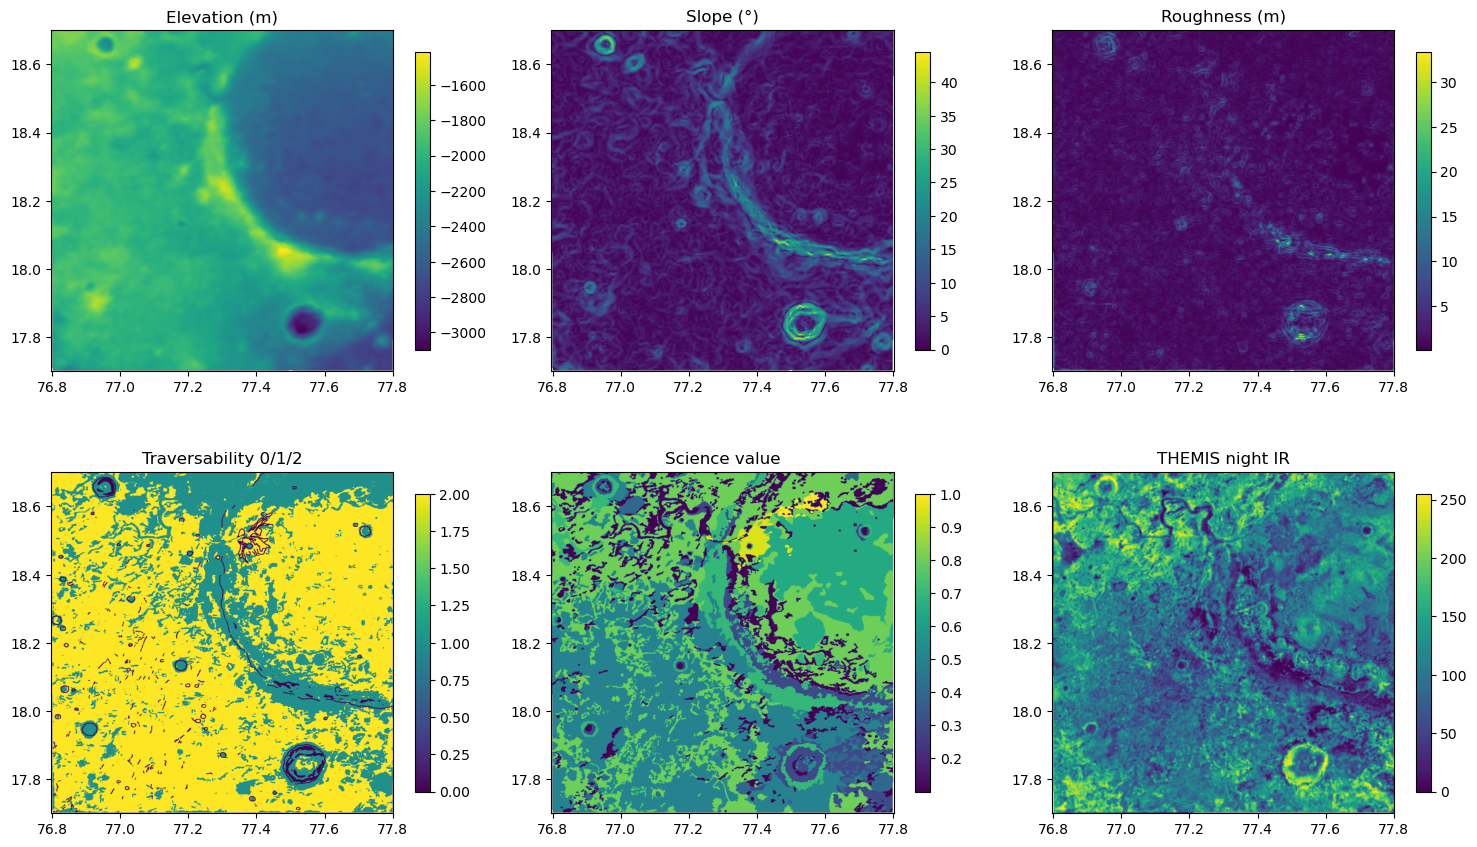

In [10]:
def colorize(a, cmap, lo, hi, alpha=1.0):
    t = np.clip((np.nan_to_num(a, nan=lo) - lo) / (hi - lo), 0, 1)
    rgba = (cm.get_cmap(cmap)(t) * 255).astype(np.uint8)
    rgba[..., 3] = np.where(np.isnan(a), 0, int(alpha * 255)); return Image.fromarray(rgba, "RGBA")

zlo, zhi = np.nanpercentile(w_dem, [1, 99])
colorize(w_dem, "terrain", zlo, zhi).save(OUT / "elevation.png", optimize=True)
colorize(w_slope, "YlOrRd", 0, 35, 0.85).save(OUT / "slope.png", optimize=True)
colorize(w_sci, "viridis", 0, 1, 0.8).save(OUT / "science.png", optimize=True)

palette = np.array([[220, 38, 38, 190], [245, 158, 11, 150], [34, 197, 94, 70]], np.uint8)       # no-go / caution / nominal
ci = np.nan_to_num(w_cls, nan=2).astype(int); trav = palette[ci]; trav[~valid] = 0
Image.fromarray(trav, "RGBA").save(OUT / "traversability.png", optimize=True)

data = np.zeros((G["h"], G["w"], 4), np.uint8)
data[..., 0] = np.clip(np.nan_to_num(w_slope) * 4, 0, 255)
data[..., 1] = np.clip(np.nan_to_num(w_cost, nan=9) * 40, 0, 255)
data[..., 2] = np.where(valid, np.nan_to_num(w_cls, nan=2), 255)
data[..., 3] = 255
Image.fromarray(data, "RGBA").save(OUT / "grid_data.png", optimize=True)
enc = np.clip((np.nan_to_num(w_dem) + 4096) * 8, 0, 65535).astype(np.uint16)
elev = np.dstack([enc >> 8, enc & 255, np.zeros_like(enc), np.full_like(enc, 255)]).astype(np.uint8)
Image.fromarray(elev, "RGBA").save(OUT / "grid_elev.png", optimize=True)

fig, ax = plt.subplots(2, 3, figsize=(15, 9))
ext = [WEST, EAST, SOUTH, NORTH]
for a_, im_, t_ in zip(ax.ravel(),
    [w_dem, w_slope, w_rough, np.nan_to_num(w_cls, nan=np.nan), w_sci, w_night],
    ["Elevation (m)", "Slope (°)", "Roughness (m)", "Traversability 0/1/2", "Science value", "THEMIS night IR"]):
    s = a_.imshow(im_, extent=ext, cmap="viridis" if "Sci" in t_ else None); a_.set_title(t_); plt.colorbar(s, ax=a_, shrink=.7)
plt.tight_layout(); plt.show()

## 9 · Vector overlays (GeoJSON) and science targets

In [11]:
def clean(g):
    g = shp_transform(to_ll.transform, g)
    g = g.intersection(AOI)
    return None if g.is_empty else shapely.set_precision(g.simplify(0.0003, preserve_topology=True), 1e-5)

def write_geojson(name, gdf, props, minarea=0):
    feats = []
    for _, row in gdf.iterrows():
        g = clean(row.geometry)
        if g is None or (minarea and g.geom_type.endswith("Polygon") and g.area < minarea): continue
        feats.append({"type": "Feature", "properties": {p: (row[p] if not isinstance(row[p], (np.generic,)) else row[p].item()) for p in props},
                      "geometry": mapping(g)})
    (OUT / name).write_text(json.dumps({"type": "FeatureCollection", "features": feats}, separators=(",", ":")))
    print(f"{name:22s} {len(feats):5d} features {(OUT / name).stat().st_size / 1024:7.0f} KB")

tab = plt.get_cmap("tab20")
units["color"] = [("#%02x%02x%02x" % tuple(int(c * 255) for c in tab(UNIT_NAMES.index(n) % 20)[:3])) if n in UNIT_NAMES else "#888888" for n in units["name"]]
units["cost"] = [UNIT_RULES.get(n, (DEFAULT_COST,))[0] for n in units["name"]]
units["science"] = [UNIT_RULES.get(n, (0, DEFAULT_SCIENCE))[1] for n in units["name"]]
units["note"] = [UNIT_RULES.get(n, ("", "", "Unclassified"))[2] for n in units["name"]]
write_geojson("geology_units.geojson", units, ["name", "color", "cost", "science", "note"], minarea=2e-7)
write_geojson("linear_features.geojson", lines, ["TYPE"])
write_geojson("surface_features.geojson", surf, ["TYPE"], minarea=2e-7)
write_geojson("craters.geojson", craters, ["TYPE"])
ellipse["label"] = ellipse["name"].astype(str)
write_geojson("landing_ellipse.geojson", ellipse, ["label"])

geology_units.geojson   1304 features    2620 KB
linear_features.geojson   382 features     114 KB
surface_features.geojson   285 features     627 KB
craters.geojson          341 features      44 KB
landing_ellipse.geojson     1 features       2 KB


surface_features.geojson   285 features     372 KB
craters.geojson          341 features      39 KB
landing_ellipse.geojson     1 features       1 KB


In [12]:
# Science targets: for every high-value unit pick the point deepest inside it that is still walkable.
targets = []
interior = np.zeros((H, W), bool); interior[12:-12, 12:-12] = True       # keep targets ~1 km inside the data edge
for k, nm in enumerate(UNIT_NAMES):
    cost, sci, why = UNIT_RULES[nm]
    if sci < 0.6: continue
    m = (unit_idx == k) & (cls > 0) & interior
    if m.sum() < 40: continue
    dist = ndi.distance_transform_edt(m)
    rr, cc = np.unravel_index(np.argmax(dist), dist.shape)
    lon, lat = to_ll.transform(X0 + (cc + .5) * RES, Y0 - (rr + .5) * RES)
    targets.append(dict(id=f"T{len(targets)+1}", name=nm.replace(" unit", ""), unit=nm, lat=round(lat, 5), lon=round(lon, 5),
                        science=sci, slopeDeg=round(float(slope[rr, cc]), 1), elevationM=round(float(dem[rr, cc])),
                        terrainClass=int(cls[rr, cc]), reason=why))
cx, cy = ellipse.geometry.iloc[0].centroid.coords[0]
lon0, lat0 = to_ll.transform(cx, cy)
start = dict(id="BASE", name="Landing ellipse centre (start)", lat=round(lat0, 5), lon=round(lon0, 5))
targets.sort(key=lambda t: -t["science"])
pd.DataFrame(targets)[["id", "name", "lat", "lon", "science", "slopeDeg", "elevationM", "terrainClass"]]

,id,name,lat,lon,science,slopeDeg,elevationM,terrainClass
0,T1,Jezero fan 1,18.62347,77.56869,1.00,0.2,-2475,2
1,T2,Jezero fan 2,18.48302,77.41788,0.95,2.6,-2456,2
2,T4,Upper etched,18.62972,77.31633,0.80,1.0,-2090,1
3,T5,Lower etched,18.24501,77.74174,0.80,1.6,-2723,2
4,T3,Nili Planum fan,18.60746,76.93586,0.70,4.7,-1890,1
5,T7,Crater rim,18.41964,77.27788,0.70,11.4,-1752,1
6,T6,Jezero floor,18.46909,77.59398,0.65,0.7,-2606,2


## 10 · Cross-check with MOLA (global DEM, 463 m)
HRSC is local and sharp; MOLA is the global reference. If both agree on absolute elevation, the layers are trustworthy.
MOLA tile `MEGT44N000HB`: lat 0–44°N, lon 0–90°E, 128 px/°, big-endian int16, metres above the areoid.

HRSC − MOLA: {'meanDiffM': 3.3, 'rmsM': 30.8, 'corr': 0.995}


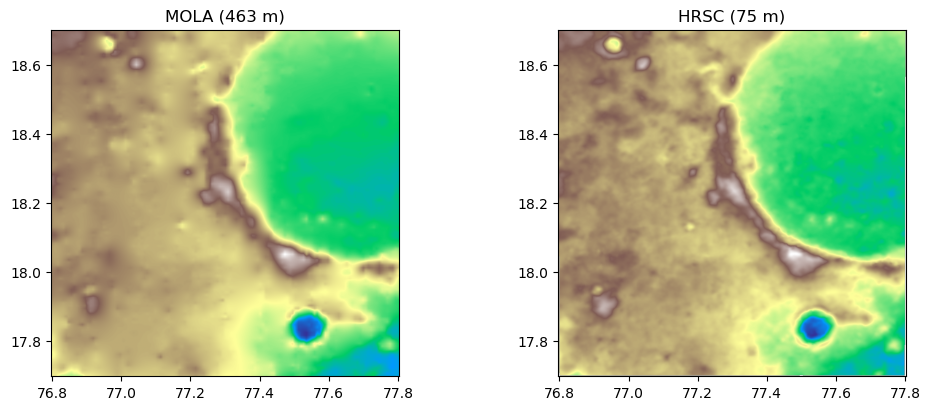

In [13]:
mola = np.fromfile(RAW / "MOLA" / "megt44n000hb.img", dtype=">i2").reshape(5632, 11520)
col = G["lon"][None, :].repeat(G["h"], 0) * 128 - 0.5; row = (44 - G["lat"][:, None].repeat(G["w"], 1)) * 128 - 0.5
w_mola = ndi.map_coordinates(mola.astype(np.float32), [row, col], order=1)
diff = (w_dem - w_mola)[valid]
mola_check = dict(meanDiffM=round(float(np.nanmean(diff)), 1), rmsM=round(float(np.sqrt(np.nanmean(diff ** 2))), 1),
                  corr=round(float(np.corrcoef(w_dem[valid], w_mola[valid])[0, 1]), 3))
print("HRSC − MOLA:", mola_check)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].imshow(w_mola, extent=ext, cmap="terrain"); ax[0].set_title("MOLA (463 m)")
ax[1].imshow(w_dem, extent=ext, cmap="terrain"); ax[1].set_title("HRSC (75 m)"); plt.show()

## 11 · MEDA index features (which sols / seasons / hours have data)
The two MEDA CSVs in the zip are **PDS product indexes**, not measurements. We engineer *coverage* features from them
(solar longitude Ls → season, local mean solar time → hour) so the app knows which observations exist
before fetching the real data files by `URN`.

In [14]:
def season(ls): return "Northern spring" if ls < 90 else "Northern summer" if ls < 180 else "Northern autumn" if ls < 270 else "Northern winter"
def hour(s):                                           # "00001M16:02:05.959" -> 16.03
    try: h, m, sec = s.split("M")[1].split(":"); return round(int(h) + int(m) / 60 + float(sec) / 3600, 2)
    except Exception: return None

meda = {}
with zipfile.ZipFile(ZIP_PATH) as z:
    for key, member in {"ancillary": "MEDA/MARS2020_MEDA_ANC_Derived_Del10.csv", "wind": "MEDA/MARS2020+MEDA_WIND_Derived_del-1-8.csv"}.items():
        df = pd.read_csv(z.open("Marsline_NASA_Resources/" + member), skipinitialspace=True)
        df.columns = [c.strip() for c in df.columns]
        ls = pd.to_numeric(df["start_solar_longitude"], errors="coerce")
        meda[key] = pd.DataFrame({
            "sol": pd.to_numeric(df["start_sol_number"], errors="coerce"), "ls": ls.round(1),
            "season": ls.map(lambda v: season(v) if pd.notna(v) else None),
            "startHour": df["start_local_mean_solar_time"].map(hour), "stopHour": df["stop_local_mean_solar_time"].map(hour),
            "sizeMB": df["File Size (MB)"], "urn": df["URN"]}).dropna(subset=["sol"])
        meda[key]["sol"] = meda[key]["sol"].astype(int)
    for k_, d_ in meda.items(): print(k_, len(d_), "sols", d_["sol"].min(), "→", d_["sol"].max())
cover = {k_: {"sols": len(d_), "bySeason": d_["season"].value_counts().to_dict(),
              "rows": d_.where(d_.notna(), None).to_dict("records")} for k_, d_ in meda.items()}
(OUT / "meda_coverage.json").write_text(json.dumps(cover, separators=(",", ":")))
print("meda_coverage.json", (OUT / "meda_coverage.json").stat().st_size // 1024, "KB")

ancillary 1063 sols 1 → 1139
wind 265 sols 36 → 315
meda_coverage.json 251 KB


## 12 · Write the metadata the app reads

In [15]:
meta = {
    "version": 1, "region": "Jezero Crater & delta (Nili Fossae, Mars)", "crs": "Mars 2000 sphere, lon/lat east-positive",
    "bounds": {"west": WEST, "east": EAST, "south": SOUTH, "north": NORTH},
    "grid": {"width": G["w"], "height": G["h"], "dlon": G["dlon"], "dlat": G["dlat"], "stepM": 75, "mPerDeg": M_PER_DEG},
    "thresholds": {"slopeBlockDeg": SLOPE_BLOCK_DEG, "slopeCautionDeg": SLOPE_CAUTION_DEG, "roughCautionM": ROUGH_CAUTION_M},
    "encoding": {"grid_data.png": "R=slope*4 (deg), G=route cost*40, B=class 0 no-go/1 caution/2 nominal/255 outside",
                 "grid_elev.png": "(R*256+G)/8 - 4096 = elevation metres"},
    "start": start, "targets": targets, "traversabilityShare": share, "molaCheck": mola_check,
    "elevationRangeM": [round(float(np.nanmin(w_dem))), round(float(np.nanmax(w_dem)))],
    "assumptions": "Slope limits and geologic-unit costs/science scores are concept-level assumptions, not NASA-certified values.",
    "layers": [
        {"id": "ctx", "title": "CTX optical mosaic", "file": "ctx.jpg", "dataType": "OPTICAL", "source": "MRO CTX · Caltech mosaic (Feb 2018)", "resolution": "5 m (shown at 20 m)"},
        {"id": "hillshade", "title": "HRSC hillshade", "file": "hillshade.png", "dataType": "TOPOGRAPHIC", "source": "Mars Express HRSC · USGS SIM 3464", "resolution": "75 m"},
        {"id": "elevation", "title": "Elevation", "file": "elevation.png", "dataType": "TOPOGRAPHIC", "source": "Mars Express HRSC DTM (checked vs MGS MOLA)", "resolution": "75 m"},
        {"id": "slope", "title": "Slope", "file": "slope.png", "dataType": "DERIVED", "source": "Derived from HRSC DTM (Horn)", "resolution": "75 m"},
        {"id": "themis_day", "title": "THEMIS day infrared", "file": "themis_day.png", "dataType": "THERMAL", "source": "Mars Odyssey THEMIS controlled mosaic (Oct 2018)", "resolution": "100 m"},
        {"id": "themis_night", "title": "THEMIS night infrared", "file": "themis_night.png", "dataType": "THERMAL", "source": "Mars Odyssey THEMIS controlled mosaic (Oct 2018)", "resolution": "100 m"},
        {"id": "geology", "title": "Geologic units", "file": "geology_units.geojson", "dataType": "GEOLOGIC", "source": "USGS SIM 3464 (Jezero & Nili Fossae)", "resolution": "map scale 1:75,000"},
        {"id": "science", "title": "Science value", "file": "science.png", "dataType": "DERIVED", "source": "Derived from USGS units (assumption-based score)", "resolution": "75 m"},
        {"id": "traversability", "title": "Traversability", "file": "traversability.png", "dataType": "DERIVED", "source": "Slope + roughness + geology + scarps", "resolution": "75 m"},
    ],
}
meta["gridBounds"] = grid_bounds(G)
for L_ in meta["layers"]:
    if L_["file"].endswith((".png", ".jpg")):
        L_["bounds"] = grid_bounds(GC if L_["id"] == "ctx" else G)
(OUT / "meta.json").write_text(json.dumps(meta, indent=1))
for p in sorted(OUT.iterdir()): print(f"{p.name:26s}{p.stat().st_size/1024:9.0f} KB")
print("TOTAL", round(sum(p.stat().st_size for p in OUT.iterdir()) / 1e6, 1), "MB")

craters.geojson                  44 KB
ctx.jpg                        1794 KB
elevation.png                   330 KB
geology_units.geojson          2620 KB
grid_data.png                   680 KB
grid_elev.png                   622 KB
hillshade.png                   234 KB
landing_ellipse.geojson           2 KB
linear_features.geojson         114 KB
meda_coverage.json              252 KB
meta.json                         6 KB
science.png                     306 KB
slope.png                       557 KB
surface_features.geojson        627 KB
themis_day.png                  467 KB
themis_night.png                555 KB
traversability.png               53 KB
TOTAL 9.5 MB
